In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("D:/Github Portfolio project 1/kepler-exoplanet-project/data/cumulative.csv")

print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [3]:
print(df['koi_disposition'].value_counts(dropna=False))

koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


In [4]:
null_percentages = (df.isnull().sum() / len(df)) * 100
print(null_percentages[null_percentages > 0].sort_values(ascending=False))

koi_teq_err1         100.000000
koi_teq_err2         100.000000
kepler_name           76.014220
koi_score             15.788373
koi_steff_err2         5.050188
koi_slogg_err1         4.893350
koi_slogg_err2         4.893350
koi_srad_err2          4.893350
koi_steff_err1         4.893350
koi_srad_err1          4.893350
koi_period_err2        4.746968
koi_period_err1        4.746968
koi_depth_err1         4.746968
koi_depth_err2         4.746968
koi_time0bk_err1       4.746968
koi_time0bk_err2       4.746968
koi_duration_err2      4.746968
koi_duration_err1      4.746968
koi_impact_err1        4.746968
koi_impact_err2        4.746968
koi_prad_err2          3.795483
koi_teq                3.795483
koi_prad               3.795483
koi_prad_err1          3.795483
koi_impact             3.795483
koi_depth              3.795483
koi_steff              3.795483
koi_model_snr          3.795483
koi_srad               3.795483
koi_slogg              3.795483
koi_tce_delivname      3.617733
koi_tce_

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 50 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              9564 non-null   int64  
 1   kepid              9564 non-null   int64  
 2   kepoi_name         9564 non-null   str    
 3   kepler_name        2294 non-null   str    
 4   koi_disposition    9564 non-null   str    
 5   koi_pdisposition   9564 non-null   str    
 6   koi_score          8054 non-null   float64
 7   koi_fpflag_nt      9564 non-null   int64  
 8   koi_fpflag_ss      9564 non-null   int64  
 9   koi_fpflag_co      9564 non-null   int64  
 10  koi_fpflag_ec      9564 non-null   int64  
 11  koi_period         9564 non-null   float64
 12  koi_period_err1    9110 non-null   float64
 13  koi_period_err2    9110 non-null   float64
 14  koi_time0bk        9564 non-null   float64
 15  koi_time0bk_err1   9110 non-null   float64
 16  koi_time0bk_err2   9110 non-null   

In [6]:
df_binary = df[df['koi_disposition'].isin(['CONFIRMED', 'FALSE POSITIVE'])].copy()

In [7]:
df_binary['target'] = df_binary['koi_disposition'].map({'CONFIRMED': 1, 'FALSE POSITIVE': 0})

print("Target count:\n", df_binary['target'].value_counts())

Target count:
 target
0    5023
1    2293
Name: count, dtype: int64


In [9]:
# 1. List of metadata and leakage columns to be dropped
cols_to_drop = [
    'rowid', 'kepid', 'kepoi_name', 'kepler_name',
    'koi_disposition', 'koi_pdisposition', 'koi_score',
    'koi_tce_delivname', 'koi_tce_plnt_num'
]

# 2. Finding all measurement error columns (_err1, _err2)
error_cols = [col for col in df_binary.columns if 'err1' in col or 'err2' in col]
cols_to_drop.extend(error_cols)

# Dropping the columns
df_clean = df_binary.drop(columns=cols_to_drop, errors='ignore')

print("Remaining columns after cleaning:", df_clean.shape[1])
print(df_clean.columns.tolist())

Remaining columns after cleaning: 20
['koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_time0bk', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_model_snr', 'koi_steff', 'koi_slogg', 'koi_srad', 'ra', 'dec', 'koi_kepmag', 'target']


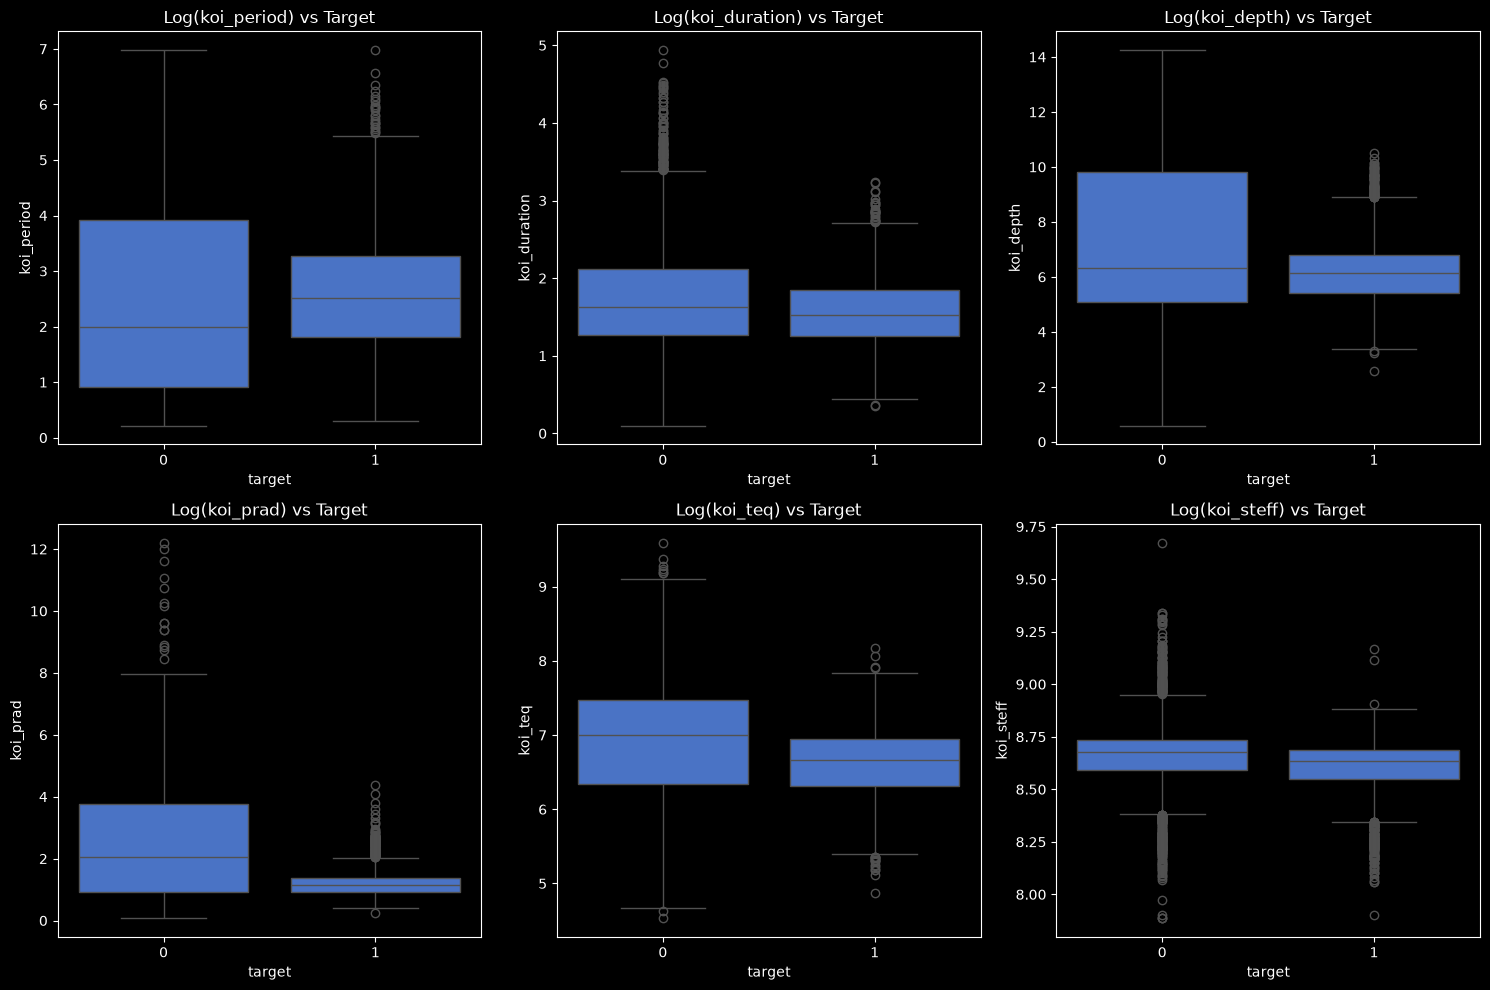

In [11]:
features_to_plot = ['koi_period', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_steff']

plt.figure(figsize=(15, 10))
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='target', y=np.log1p(df_clean[col]), data=df_clean)
    plt.title(f'Log({col}) vs Target')
plt.tight_layout()
plt.show()


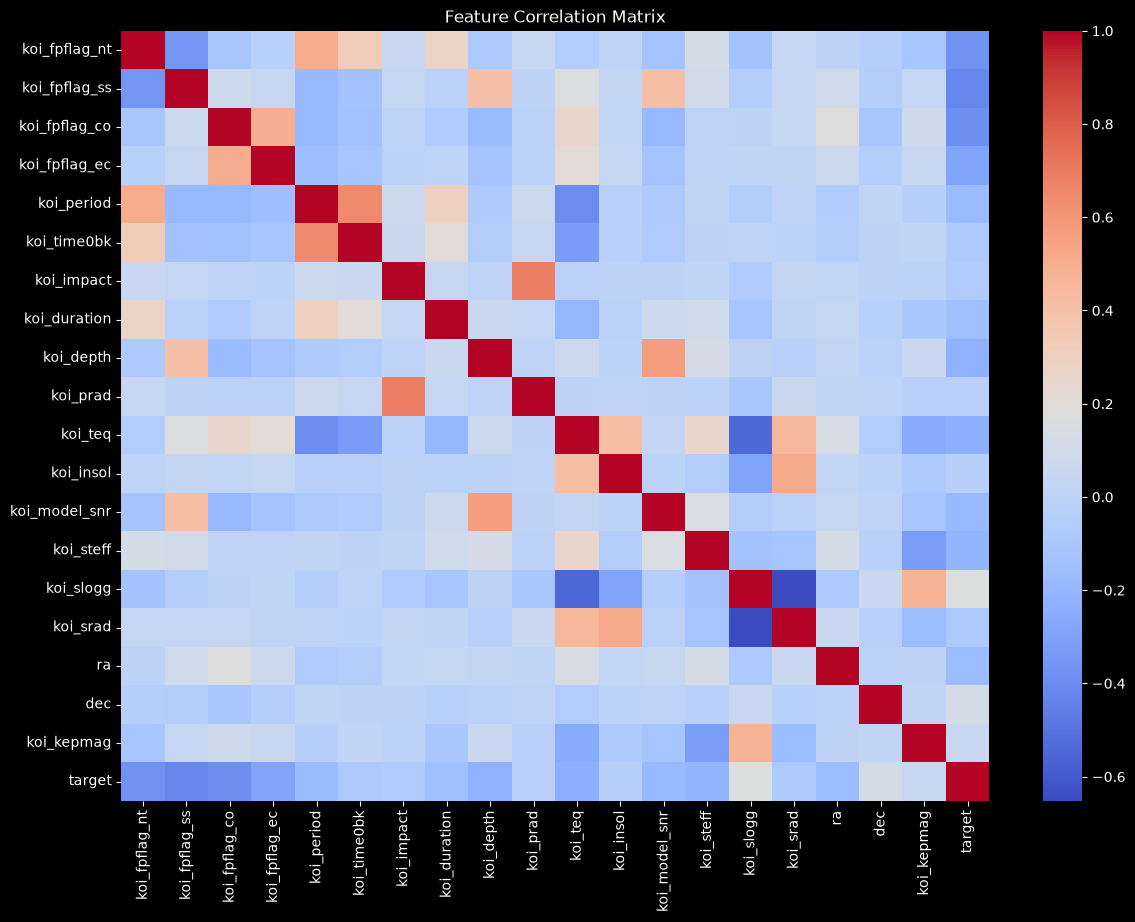

In [12]:
plt.figure(figsize=(14, 10))
sns.heatmap(df_clean.corr(), annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline

# 1. Splitting into Features (X) and Target (y)
X = df_clean.drop(columns=['target'])
y = df_clean['target']

# 2. Splitting into Train (80%) and Test (20%) (stratified to maintain class proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Building the preprocessing pipeline
# Median Imputer and RobustScaler are best suited for space data with many outliers
preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Fit_transform on train data and transform only on test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train shape:", X_train_processed.shape)
print("X_test shape:", X_test_processed.shape)

X_train shape: (5852, 19)
X_test shape: (1464, 19)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

# Models to test
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42)
}

results = []

for name, model in models.items():
    # Training the model
    model.fit(X_train_processed, y_train)

    # Making predictions
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculating metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Viewing the results in a table
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression  0.980874   0.963441 0.976035  0.969697 0.994466
      Random Forest  0.986339   0.993258 0.962963  0.977876 0.996304
  Gradient Boosting  0.987022   0.984581 0.973856  0.979189 0.997871


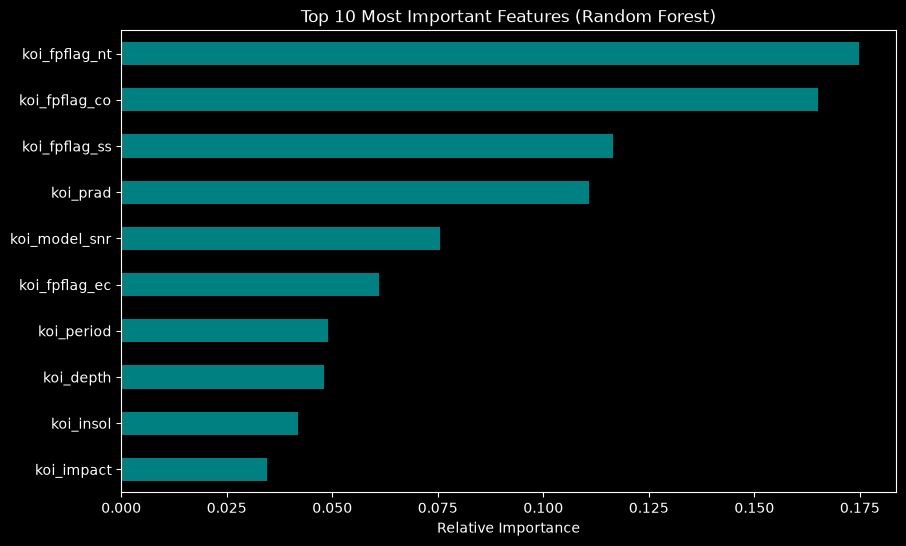

In [15]:
rf_model = models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=X.columns)

plt.figure(figsize=(10, 6))
importances.nlargest(10).sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Most Important Features (Random Forest)')
plt.xlabel('Relative Importance')
plt.show()

In [16]:
# Adding new physics-based features on top of df_clean
df_fe = df_clean.copy()

# 1. Planet-to-Star Radius Ratio
# In a transit event, the dimming of light is directly proportional to the square of this ratio
df_fe['radius_ratio'] = df_fe['koi_prad'] / (df_fe['koi_srad'] * 109.1) # 1 Solar radius ≈ 109.1 Earth radii

# 2. Transit Duty Cycle
# If a planet's transit duration across the star is unusually long, it is more likely an eclipsing binary
df_fe['transit_duty_cycle'] = (df_fe['koi_duration'] / 24.0) / df_fe['koi_period']

# 3. Normalized Transit Depth
df_fe['depth_to_snr_ratio'] = df_fe['koi_depth'] / (df_fe['koi_model_snr'] + 1e-5)

# Replace any infinite values with NaN (the imputer will fill them)
df_fe.replace([np.inf, -np.inf], np.nan, inplace=True)

# Redefine X and y and perform train-test split again
X = df_fe.drop(columns=['target'])
y = df_fe['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [17]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

# Defining the parameter grid
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced', None]
}

rf = RandomForestClassifier(random_state=42)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Searching for the best parameters using RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1',
    cv=cv_strategy,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_processed, y_train)

best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)
print("Best CV F1-Score:", random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30, 'class_weight': 'balanced'}
Best CV F1-Score: 0.9814992725858627


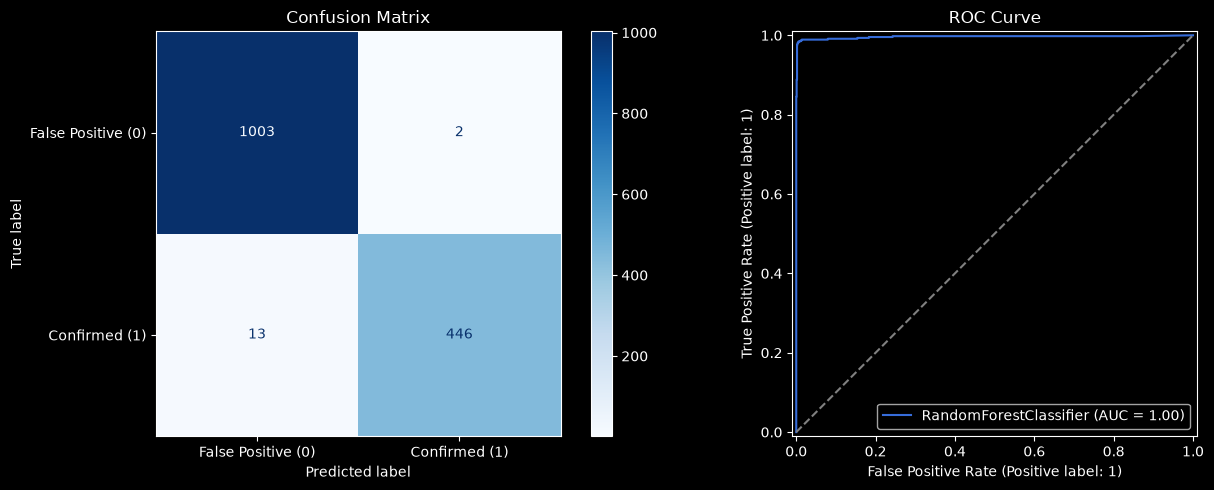

                precision    recall  f1-score   support

FALSE POSITIVE       0.99      1.00      0.99      1005
     CONFIRMED       1.00      0.97      0.98       459

      accuracy                           0.99      1464
     macro avg       0.99      0.98      0.99      1464
  weighted avg       0.99      0.99      0.99      1464



In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

y_pred_best = best_model.predict(X_test_processed)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test_processed, y_test,
    display_labels=['False Positive (0)', 'Confirmed (1)'],
    cmap='Blues', ax=ax[0]
)
ax[0].set_title('Confusion Matrix')

# 2. ROC Curve
RocCurveDisplay.from_estimator(best_model, X_test_processed, y_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
ax[1].set_title('ROC Curve')

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_best, target_names=['FALSE POSITIVE', 'CONFIRMED']))

In [19]:
# 1. Extracting only the CANDIDATE objects from the original dataset
df_candidates = df[df['koi_disposition'] == 'CANDIDATE'].copy()

# 2. Applying the exact same feature engineering to the candidate data
df_candidates['radius_ratio'] = df_candidates['koi_prad'] / (df_candidates['koi_srad'] * 109.1)
df_candidates['transit_duty_cycle'] = (df_candidates['koi_duration'] / 24.0) / df_candidates['koi_period']
df_candidates['depth_to_snr_ratio'] = df_candidates['koi_depth'] / (df_candidates['koi_model_snr'] + 1e-5)
df_candidates.replace([np.inf, -np.inf], np.nan, inplace=True)

# 3. Selecting the exact same feature columns used during training
X_candidates = df_candidates[X.columns]

# 4. Transforming with the preprocessor and predicting
X_candidates_processed = preprocessor.transform(X_candidates)
df_candidates['predicted_class'] = best_model.predict(X_candidates_processed)
df_candidates['exoplanet_probability'] = best_model.predict_proba(X_candidates_processed)[:, 1]

# 5. Displaying the top 10 candidates with an exoplanet probability of 95% or higher
top_candidates = df_candidates[df_candidates['exoplanet_probability'] >= 0.95].sort_values(
    by='exoplanet_probability', ascending=False
)

print(f"Out of a total of {len(df_candidates)} candidates, the number predicted as real planets by the model: {(df_candidates['predicted_class'] == 1).sum()}")
print("\nTop 10 Candidates with the Highest Planet Probability:")
print(top_candidates[['kepoi_name', 'koi_period', 'koi_prad', 'koi_teq', 'exoplanet_probability']].head(10))

Out of a total of 2248 candidates, the number predicted as real planets by the model: 1594

Top 10 Candidates with the Highest Planet Probability:
     kepoi_name  koi_period  koi_prad  koi_teq  exoplanet_probability
5026  K03347.01   12.902359      1.49    675.0                    1.0
5857  K01871.02   32.376183      2.26    392.0                    1.0
353   K01051.01    6.796854      2.01    985.0                    1.0
4543  K03319.01   19.590610      2.64    819.0                    1.0
4999  K03341.01   27.096515      2.13    700.0                    1.0
5038  K03493.01   46.716234      2.03    531.0                    1.0
3350  K00691.01   29.666317      2.83    644.0                    1.0
3178  K00558.01    9.178585      2.30    753.0                    1.0
2948  K00577.01   39.676607      2.29    473.0                    1.0
3090  K00592.01   39.752992      2.37    568.0                    1.0


In [20]:
import joblib
import os

os.makedirs('models', exist_ok=True)

# Saving the preprocessor and best model together as a single pipeline
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_model)
])

joblib.dump(full_pipeline, 'models/kepler_exoplanet_pipeline.pkl')
joblib.dump(X.columns.tolist(), 'models/feature_names.pkl')
print("Model pipeline saved successfully in 'models/' directory!")

Model pipeline saved successfully in 'models/' directory!


In [21]:
habitable_candidates = top_candidates[
    (top_candidates['koi_prad'].between(0.8, 2.0)) &
    (top_candidates['koi_teq'].between(180, 310))
]
print("Potentially Habitable Candidates found by Model:")
print(habitable_candidates[['kepoi_name', 'koi_prad', 'koi_teq', 'exoplanet_probability']])

Potentially Habitable Candidates found by Model:
     kepoi_name  koi_prad  koi_teq  exoplanet_probability
1794  K02290.01      1.82    310.0               0.980000
2722  K03034.01      1.66    291.0               0.973448
2256  K02626.01      1.58    242.0               0.964630


In [22]:
from scipy.stats import mannwhitneyu

# Since the data is not normally distributed, we will use the Mann-Whitney U Test
confirmed_depth = df_clean[df_clean['target'] == 1]['koi_depth'].dropna()
fp_depth = df_clean[df_clean['target'] == 0]['koi_depth'].dropna()

stat, p_value = mannwhitneyu(confirmed_depth, fp_depth)

print(f"Mann-Whitney U Statistic: {stat:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("Result: Reject Null Hypothesis (The transit depths of CONFIRMED and FALSE POSITIVE are significantly different)")
else:
    print("Result: Fail to Reject Null Hypothesis")

Mann-Whitney U Statistic: 4734495.0000
P-value: 1.3892e-17
Result: Reject Null Hypothesis (The transit depths of CONFIRMED and FALSE POSITIVE are significantly different)


In [26]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Loading the saved model and feature list
pipeline = joblib.load('models/kepler_exoplanet_pipeline.pkl')
feature_names = joblib.load('models/feature_names.pkl')

st.set_page_config(page_title="NASA Kepler Exoplanet Classifier", layout="wide")
st.title("🪐 NASA Kepler Exoplanet Search & Classification")
st.write("A system that classifies objects as a real exoplanet (`CONFIRMED`) or a false alarm (`FALSE POSITIVE`) based on transit photometry measurements.")

st.sidebar.header("Input Planetary & Stellar Parameters")

# Receiving key features from the user
koi_period = st.sidebar.number_input("Orbital Period (days)", min_value=0.1, value=10.5)
koi_duration = st.sidebar.number_input("Transit Duration (hours)", min_value=0.1, value=3.2)
koi_depth = st.sidebar.number_input("Transit Depth (ppm)", min_value=1.0, value=500.0)
koi_prad = st.sidebar.number_input("Planetary Radius (Earth radii)", min_value=0.1, value=1.5)
koi_teq = st.sidebar.number_input("Equilibrium Temperature (K)", min_value=50.0, value=280.0)
koi_srad = st.sidebar.number_input("Stellar Radius (Solar radii)", min_value=0.1, value=1.0)
koi_model_snr = st.sidebar.number_input("Transit Signal-to-Noise Ratio (SNR)", min_value=1.0, value=25.0)

if st.sidebar.button("Predict Disposition"):
    # Creating a DataFrame with default NaNs for all features (the imputer will fill the rest with the median)
    input_data = pd.DataFrame(columns=feature_names)
    input_data.loc[0] = np.nan

    # Assigning the values provided by the user
    input_data['koi_period'] = koi_period
    input_data['koi_duration'] = koi_duration
    input_data['koi_depth'] = koi_depth
    input_data['koi_prad'] = koi_prad
    input_data['koi_teq'] = koi_teq
    input_data['koi_srad'] = koi_srad
    input_data['koi_model_snr'] = koi_model_snr

    # Calculating engineered features
    if 'radius_ratio' in feature_names:
        input_data['radius_ratio'] = koi_prad / (koi_srad * 109.1)
    if 'transit_duty_cycle' in feature_names:
        input_data['transit_duty_cycle'] = (koi_duration / 24.0) / koi_period
    if 'depth_to_snr_ratio' in feature_names:
        input_data['depth_to_snr_ratio'] = koi_depth / (koi_model_snr + 1e-5)

    # Making predictions
    pred = pipeline.predict(input_data)[0]
    prob = pipeline.predict_proba(input_data)[0][1]

    st.subheader("Prediction Result")
    if pred == 1:
        st.success(f"✅ **CONFIRMED EXOPLANET** (Confidence: {prob*100:.2f}%)")
        if 0.8 <= koi_prad <= 2.0 and 180 <= koi_teq <= 310:
            st.info("🌍 **Habitable Zone Alert:** This planet is close to Earth's size and lies within a potentially habitable temperature range!")
    else:
        st.error(f"❌ **FALSE POSITIVE** (Exoplanet Probability: {prob*100:.2f}%)")

Writing app.py
